---
execute:
  skip: true
authors:
- name: Daniel Handwerker
- name: Monika Doerig
doi: 10.5281/zenodo.18740153
github: https://github.com/neurodesk/neurodeskedu/blob/main/books/examples/functional_imaging/process_five_echo_dataset.ipynb
edit_url: https://github.dev/neurodesk/neurodeskedu/blob/main/books/examples/functional_imaging/process_five_echo_dataset.ipynb
downloads:
- url: /edu/_sources/examples/functional_imaging/process_five_echo_dataset.ipynb
  title: Download source notebook
  filename: process_five_echo_dataset.ipynb
  static: false
---
# tedana: TE Dependent ANAlysis

:::{admonition} Reviewed
:class: nd-review-badge nd-review-badge--reviewed

[review issue](<https://github.com/neurodesk/neurodeskedu-reviews/issues/19>) · [@andrewjahn](<https://github.com/andrewjahn>)
:::

:::{dropdown} Run this notebook
:class: nd-launch

- [Run in Australia](<https://play.neurodesk.cloud.edu.au/hub/user-redirect/git-pull?repo=https%3A//github.com/neurodesk/neurodeskedu&urlpath=lab/tree/neurodeskedu/books/examples/functional_imaging/process_five_echo_dataset.ipynb&branch=main>)
- [Run in Europe](<https://play-europe.neurodesk.org/hub/user-redirect/git-pull?repo=https%3A//github.com/neurodesk/neurodeskedu&urlpath=lab/tree/neurodeskedu/books/examples/functional_imaging/process_five_echo_dataset.ipynb&branch=main>)
- [Run in America](<https://play-america.neurodesk.org/hub/user-redirect/git-pull?repo=https%3A//github.com/neurodesk/neurodeskedu&urlpath=lab/tree/neurodeskedu/books/examples/functional_imaging/process_five_echo_dataset.ipynb&branch=main>)
- [Run in Global Server 1](<https://play-europe.neurodesk.org/hub/user-redirect/git-pull?repo=https%3A//github.com/neurodesk/neurodeskedu&urlpath=lab/tree/neurodeskedu/books/examples/functional_imaging/process_five_echo_dataset.ipynb&branch=main>)
- [Run in Global Server 2](<https://edu.neurodesk.org/hub/user-redirect/git-pull?repo=https%3A//github.com/neurodesk/neurodeskedu&urlpath=lab/tree/neurodeskedu/books/examples/functional_imaging/process_five_echo_dataset.ipynb&branch=main>)
:::

## Process five-echo flashing checkerboard dataset for software demo



**Date**: 23 June 2025

**License:** 
<div style="margin-top: 10px;">
    <a href="https://opensource.org/licenses/MIT" target="_blank" style="color: #0066cc;">
        <i class="fas fa-balance-scale"></i> MIT License
    </a>
</div>


**Note:** If this notebook uses neuroimaging tools from Neurocontainers, those tools retain their original licenses. Please see <a href="https://neurodesk.org/overview/how-to-cite-us/" target="_blank" style="color: #0066cc;">Neurodesk citation guidelines</a> for details.

### Citation:

   
#### Tools included in this workflow
- **tedana**: The tedana Community, Ahmed, Z., Bandettini, P. A., Bottenhorn, K. L., Caballero-Gaudes, C., Dowdle, L. T., DuPre, E., Gonzalez-Castillo, J., Handwerker, D., Heunis, S., Kundu, P., Laird, A. R., Markello, R., Markiewicz, C. J., Maullin-Sapey, T., Moia, S., Molfese, P., Salo, T., Staden, I., … Whitaker, K. (2026). ME-ICA/tedana: 26.0.3 (26.0.3). Zenodo. [https://doi.org/10.5281/zenodo.19410167](https://doi.org/10.5281/zenodo.19410167)


#### Publications
- DuPre, E. M., Salo, T., Ahmed, Z., Bandettini, P. A., Bottenhorn, K. L., Caballero-Gaudes, C., Dowdle, L. T., Gonzalez-Castillo, J., Heunis, S., Kundu, P., Laird, A. R., Markello, R., Markiewicz, C. J., Moia, S., Staden, I., Teves, J. B., Uruñuela, E., Vaziri-Pashkam, M., Whitaker, K., & Handwerker, D. A. (2021). [TE-dependent analysis of multi-echo fMRI with tedana](https://joss.theoj.org/papers/10.21105/joss.03669). Journal of Open Source Software, 6(66), 3669. doi:10.21105/joss.03669.

- Kundu, P., Inati, S. J., Evans, J. W., Luh, W. M., & Bandettini, P. A. (2011). [Differentiating BOLD and non-BOLD signals in fMRI time series using multi-echo EPI](https://doi.org/10.1016/j.neuroimage.2011.12.028). NeuroImage, 60, 1759-1770.

- Kundu, P., Brenowitz, N. D., Voon, V., Worbe, Y., Vértes, P. E., Inati, S. J., Saad, Z. S., Bandettini, P. A., & Bullmore, E. T. (2013). [Integrated strategy for improving functional connectivity mapping using multiecho fMRI.](https://www.pnas.org/doi/full/10.1073/pnas.1301725110) Proceedings of the National Academy of Sciences, 110, 16187-16192.

#### Educational resources
- [tedana documentation](https://tedana.readthedocs.io/en/stable/index.html#)

#### Dataset
- DuPre, E., Salo, T., Whitaker, K. J., Teves, J., Dowdle, L., Reynolds, R. C., & Handwerker, D. A. (2024, February 21). tedana data. Retrieved from [osf.io/bpe8h](https://osf.io/bpe8h/)

## Installations and Imports

In [1]:
%%capture
! pip install "nilearn==0.12.1" "tedana==26.0.3"

In [2]:
import module
await module.load('afni/24.3.00')
await module.list()

['afni/24.3.00']

In [3]:
%matplotlib inline
import os
import os.path as op
from glob import glob
import webbrowser
from IPython.display import display, Markdown, Image
from IPython.core.display import SVG
from tedana.workflows import tedana_workflow

## Download 5 echo data

In [4]:
%%time
dset_dir5 = 'five-echo-dataset/'
wd = os.getcwd()

if not glob(op.join(dset_dir5, 'p06*.nii.gz')):
    os.makedirs(dset_dir5, exist_ok=True)
    !curl -fL --retry 5 --retry-all-errors -o five_echo_NIH.tar.xz https://huggingface.co/datasets/neurodeskorg/tedana-five-echo/resolve/d8f66b3b25dae1e1a09537fc82f6ea3e49d840f7/five_echo_NIH.tar.xz
    !tar xf five_echo_NIH.tar.xz -C five-echo-dataset
    os.remove('five_echo_NIH.tar.xz')

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  1149  100  1149    0     0   4153      0 --:--:-- --:--:-- --:--:--  4163
100 68.5M  100 68.5M    0     0  7735k      0  0:00:09  0:00:09 --:--:-- 10.9M
CPU times: user 66.8 ms, sys: 58.1 ms, total: 125 ms
Wall time: 9.43 s


In [5]:
# Clone GitHub repo and copy files
![ -d temp_repo ] || git clone https://github.com/ME-ICA/ohbm-2025-multiecho.git temp_repo
!cp -r temp_repo/five-echo-dataset/* five-echo-dataset/
!rm -rf temp_repo

Cloning into 'temp_repo'...
remote: Enumerating objects: 156, done.
remote: Counting objects: 100% (156/156), done.
remote: Compressing objects: 100% (124/124), done.
remote: Total 156 (delta 44), reused 141 (delta 32), pack-reused 0 (from 0)
Receiving objects: 100% (156/156), 16.37 MiB | 23.25 MiB/s, done.
Resolving deltas: 100% (44/44), done.


## Run workflow on 5 echo data

In [6]:
%%time
dset_dir5_out = f"{dset_dir5}tedana_processed"
files = sorted(glob(op.join(dset_dir5, 'p06*.nii.gz')))
tes = [15.4, 29.7, 44.0, 58.3, 72.6]
tedana_workflow(files, tes, 
    tree="minimal",
    fixed_seed=42,
    ica_method="robustica",
    n_robust_runs=30,
    tedpca=53,
    out_dir=dset_dir5_out,
    tedort=False
    )

INFO     tedana:tedana_workflow:636 Using output directory: /home/jovyan/workspace/books/examples/functional_imaging/five-echo-dataset/tedana_processed
WARNING  utils:check_te_values:796 TE values appear to be in milliseconds. Per BIDS convention, echo times should be provided in seconds. Support for millisecond TE values is deprecated and will be removed in a future version. Please provide TE values in seconds.
INFO     tedana:tedana_workflow:655 Initializing and validating component selection tree
WARNING  component_selector:validate_tree:146 Decision tree includes fields that are not used or logged ['_comment']
INFO     component_selector:__init__:345 Performing component selection with minimal_decision_tree
INFO     component_selector:__init__:346 first version of minimal decision tree
INFO     io:__init__:164 Generating figures directory: /home/jovyan/workspace/books/examples/functional_imaging/five-echo-dataset/tedana_processed/figures
WARNING  utils:load_mask:943 Computing EPI m

Setting clustering defaults: {'min_samples': 15}
Running FastICA multiple times...
Inferring sign of components...
Clustering...
Computing centroids...
Computing Silhouettes...
Computing Iq...
CPU times: user 43min 7s, sys: 12.1 s, total: 43min 19s
Wall time: 4min 20s


## Tedana report of 5 echo data

You can explore an example of an interactive tedana report [here](https://me-ica.github.io/ohbm-2023-multiecho/tedana/tedana_results_minimal_five-echo/tedana_report.html).

The interactive tedana report for the current dataset is written to the path shown below.

In [7]:
# this is the path of the tedana report
report_path = os.path.relpath(dset_dir5_out + '/tedana_report.html')
print(report_path)

five-echo-dataset/tedana_processed/tedana_report.html


In [8]:
display(Markdown(
    f'📊 Interactive tedana report: open `{report_path}` '
    'in JupyterLab after running this notebook (it is not published on this website). '
    'The tedana developers publish [their report for the same data and workflow]'
    '(https://me-ica.github.io/ohbm-2025-multiecho/tedana_processed/tedana_report.html), generated with tedana 25.0.1.'
))

📊 Interactive tedana report: open `five-echo-dataset/tedana_processed/tedana_report.html` in JupyterLab after running this notebook (it is not published on this website). The tedana developers publish [their report for the same data and workflow](https://me-ica.github.io/ohbm-2025-multiecho/tedana_processed/tedana_report.html), generated with tedana 25.0.1.

Below, selected components from the generated tedana report are visualized.

### Carpet plot

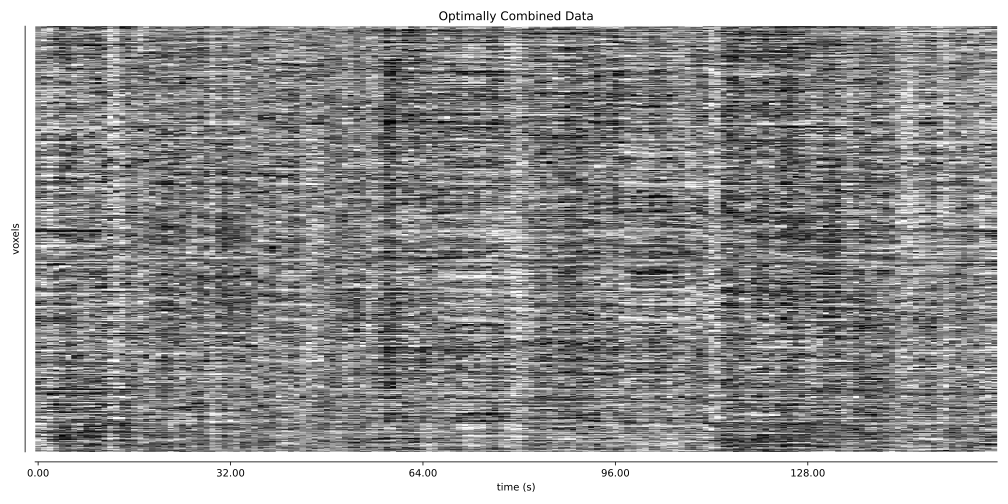

In [9]:
SVG(filename='five-echo-dataset/tedana_processed/figures/carpet_optcom.svg')

### Adaptive Mask

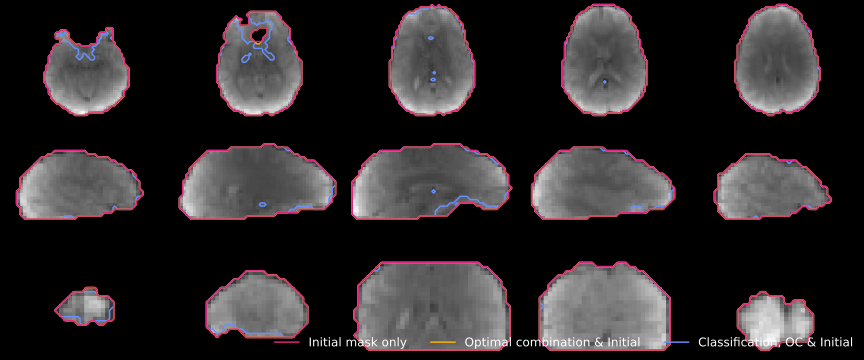

In [10]:
SVG(filename='five-echo-dataset/tedana_processed/figures/adaptive_mask.svg')

### T2*

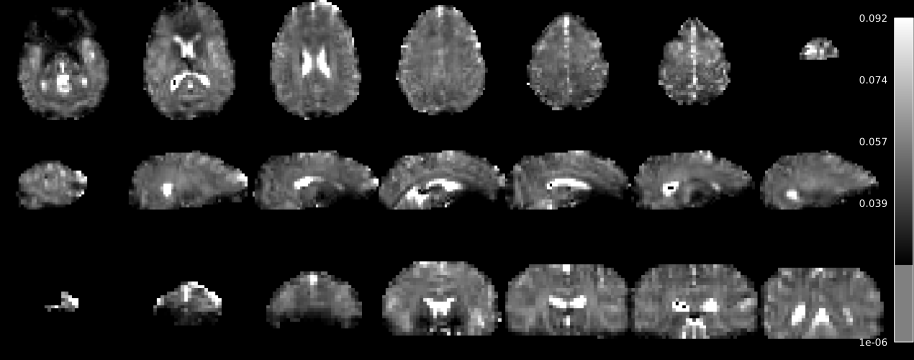

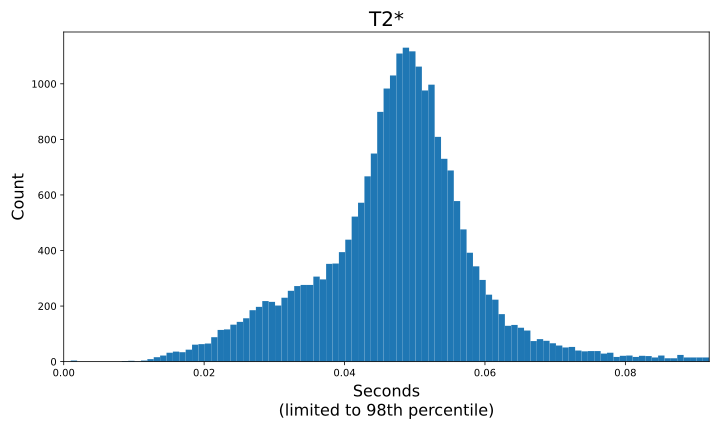

In [11]:
t2star_brain = SVG(filename='five-echo-dataset/tedana_processed/figures/t2star_brain.svg')
t2star_histogram = SVG(filename='five-echo-dataset/tedana_processed/figures/t2star_histogram.svg')

display(t2star_brain, t2star_histogram)

### S0

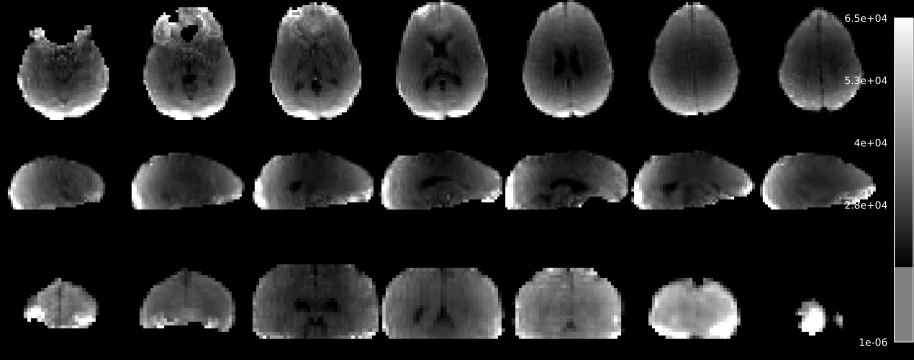

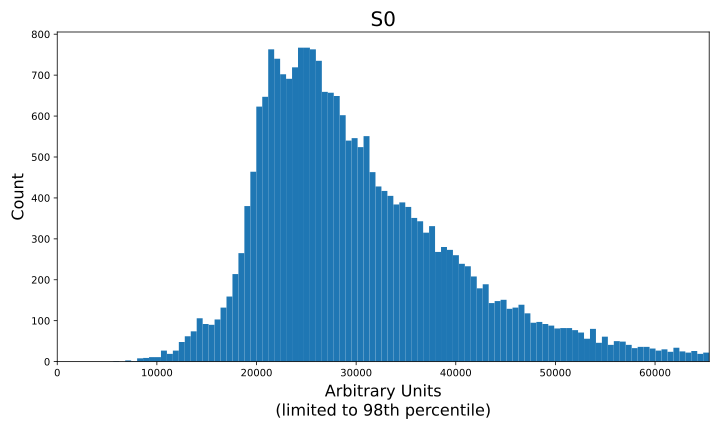

In [12]:
s0_brain = SVG(filename='five-echo-dataset/tedana_processed/figures/s0_brain.svg')
s0_histogram = SVG(filename='five-echo-dataset/tedana_processed/figures/s0_histogram.svg')

display(s0_brain, s0_histogram)

### T2* and S0 model fit (RMSE). (Scaled between 2nd and 98th percentiles)

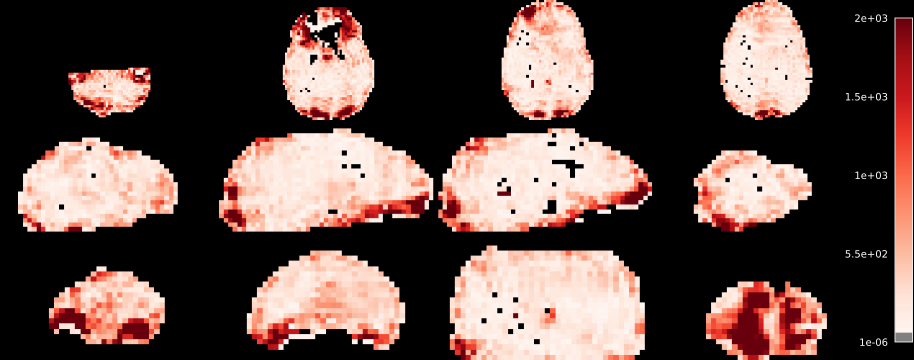

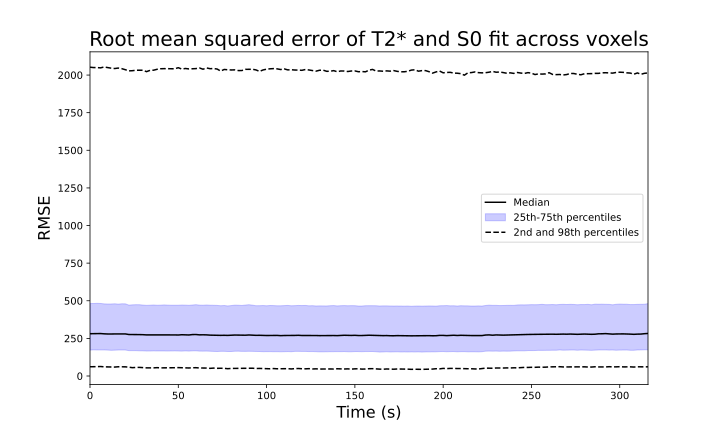

In [13]:
rmse_brain = SVG(filename='five-echo-dataset/tedana_processed/figures/rmse_brain.svg')
rmse_timeseries = SVG(filename='five-echo-dataset/tedana_processed/figures/rmse_timeseries.svg')

display(rmse_brain, rmse_timeseries)

### Time series generation using AFNI commands

In [14]:
%%bash
# A rough CSF mask for demonstration purposes
# Segment the CSF, erode by 1 voxel, #
# and retain voxels containing 75% of the CSF mask when downsampled to EPI space
cd five-echo-dataset

3dSeg -anat SBJ01_Anatomy.nii.gz -mask AUTO \
    -classes 'CSF ; GM ; WM'  \
    -bias_classes 'GM ; WM' \
    -bias_fwhm 25 -mixfrac UNI -main_N 5 \
    -blur_meth BFT
3dcalc -a ./Segsy/Classes+tlrc -expr 'equals(a, 1)' -prefix CSF_anatresolution.nii.gz
3dmask_tool -input CSF_anatresolution.nii.gz \
    -prefix CSF_eroded.nii.gz \
    -dilate_result -1 -fill_holes 
3dfractionize -template p06.SBJ01_S09_Task11_e3.sm.nii.gz \
    -prefix CSF_mask.nii.gz \
    -input CSF_eroded.nii.gz \
    -clip 0.75

# make CSF principal components
3dpc -mask CSF_mask.nii.gz -pcsave 3  \
    -prefix CSF_timeseries \
    ./tedana_processed/desc-optcom_bold.nii.gz

# Combine all external regressors into a single file
external_regress_header="mot_x\tmot_y\tmot_z\tmot_pitch\tmot_roll\tmot_yaw\t"\
"mot_dx\tmot_dy\tmot_dz\tmot_dpitch\tmot_droll\tmot_dyaw\tcsf1\tcsf2\tcsf3\t"\
"signal_checkerboard"

1dcat -tsvout \
    SBJ01_S09_Task11_e2_Motion.demean.1D \
    SBJ01_S09_Task11_e2_Motion.demean.der.1D \
    CSF_timeseries0?.1D \
    block_task_response.1D \
    > tmp.tsv

# Convert spaces to tabs and skip the header line from 1dcat
tail -n +2 tmp.tsv | tr ' ' '\t' > tmp_clean.tsv

# Add header
(echo -e "$external_regress_header"; cat tmp_clean.tsv) > external_regressors.tsv

# Clean up
rm tmp.tsv tmp_clean.tsv

*+ WARNING: +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
*+ WARNING: ss.cp+tlrc[0] scale to shorts mean misfit error = 38.4% -- **** Red Alert ****
 + a) Numerical precision has been lost when truncating results
       from 32-bit floating point to 16-bit integers (shorts).
 + b) Consider writing datasets out in float format.
       In most AFNI programs, use the '-float' option.
 + c) This warning is a new message, but is an old issue
       that arises when storing results in an integer format.
 + d) Don't panic! These messages likely originate in peripheral
       or unimportant voxels. They mean that you must examine your output.
       "Assess the situation and keep a calm head about you,
        because it doesn't do anybody any good to panic."
++ ++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
*+ WARNING: GenPriorsOut.x+tlrc[0] scale to shorts mean misfit error = 40.0% -- ***** Purple Alert! *****
*+ WARNING: GenPriorsOut.x+tlrc[0] scale to sh


++ Compile date = Oct  1 2024 {AFNI_24.3.00:linux_ubuntu_24_64}



## Run workflow on 5 echo data using existing mixing matrix and external regressors

In [15]:
%%time
dset_dir5_extern_out = f"{dset_dir5}tedana_external_regress_processed"
files = sorted(glob(op.join(dset_dir5, 'p06*.nii.gz')))
tes = [15.4, 29.7, 44.0, 58.3, 72.6]
tedana_workflow(files, tes, 
    tree="demo_external_regressors_motion_task_models",
    external_regressors=op.join(dset_dir5,"external_regressors.tsv"),
    mixing_file=op.join(dset_dir5,"tedana_processed", "desc-ICA_mixing.tsv"),
    out_dir=dset_dir5_extern_out
    )

INFO     tedana:tedana_workflow:636 Using output directory: /home/jovyan/workspace/books/examples/functional_imaging/five-echo-dataset/tedana_external_regress_processed
WARNING  utils:check_te_values:796 TE values appear to be in milliseconds. Per BIDS convention, echo times should be provided in seconds. Support for millisecond TE values is deprecated and will be removed in a future version. Please provide TE values in seconds.
INFO     tedana:tedana_workflow:655 Initializing and validating component selection tree
INFO     component_selector:__init__:345 Performing component selection with demo_external_regressors_motion_task_models
INFO     component_selector:__init__:346 Demonstration based on the minimal decision tree that uses partial F stats on a model with multiple external regressors divided by category and task regressors to bias towards keeping.
INFO     io:__init__:164 Generating figures directory: /home/jovyan/workspace/books/examples/functional_imaging/five-echo-dataset/t

(160, 40)
(160, 40)
(160, 40)
(160, 40)
CPU times: user 2min 7s, sys: 1.67 s, total: 2min 8s
Wall time: 1min 36s


## Components of the tedana report of 5 echo data with external regressors

In [16]:
# Here is the path to the second TEDANA report
report_path_ext = os.path.relpath(dset_dir5_extern_out + '/tedana_report.html')
print(report_path_ext)

five-echo-dataset/tedana_external_regress_processed/tedana_report.html


In [17]:
display(Markdown(
    f'📊 Interactive tedana report with external regressors: open `{report_path_ext}` '
    'in JupyterLab after running this notebook (it is not published on this website). '
    'The tedana developers publish [their report for the same data and workflow]'
    '(https://me-ica.github.io/ohbm-2025-multiecho/tedana_external_regress_processed/tedana_report.html), generated with tedana 25.0.1.'
))

📊 Interactive tedana report with external regressors: open `five-echo-dataset/tedana_external_regress_processed/tedana_report.html` in JupyterLab after running this notebook (it is not published on this website). The tedana developers publish [their report for the same data and workflow](https://me-ica.github.io/ohbm-2025-multiecho/tedana_external_regress_processed/tedana_report.html), generated with tedana 25.0.1.

### Carpet plot

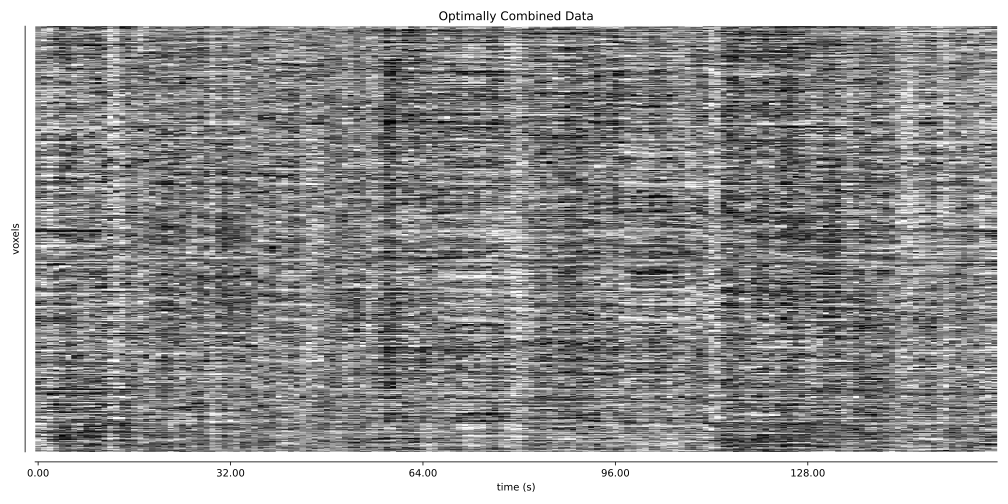

In [18]:
SVG(filename='five-echo-dataset/tedana_external_regress_processed/figures/carpet_optcom.svg')

### Adaptive Mask

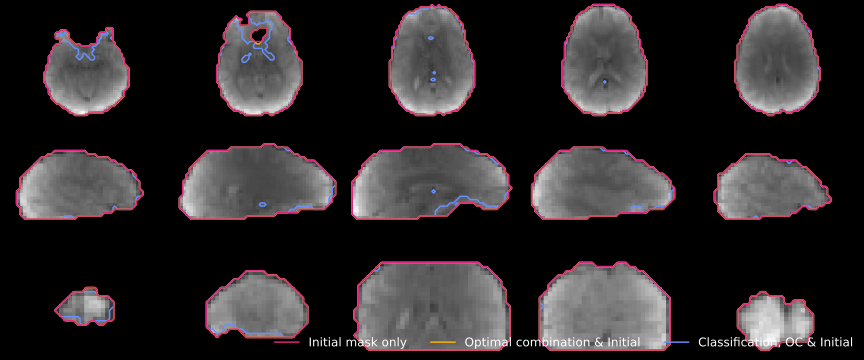

In [19]:
SVG(filename='five-echo-dataset/tedana_external_regress_processed/figures/adaptive_mask.svg')

### T2*

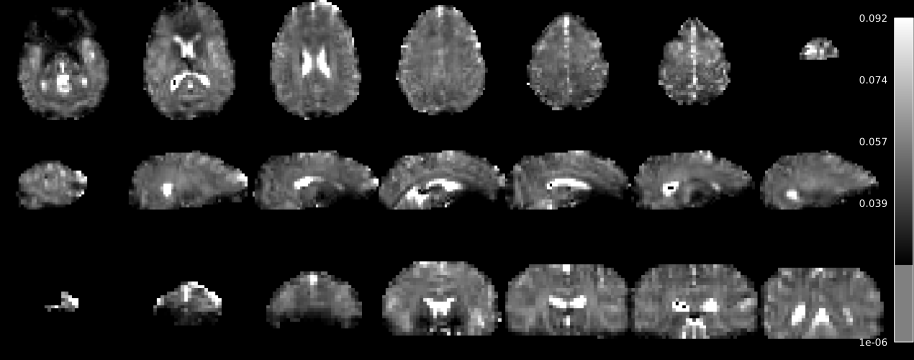

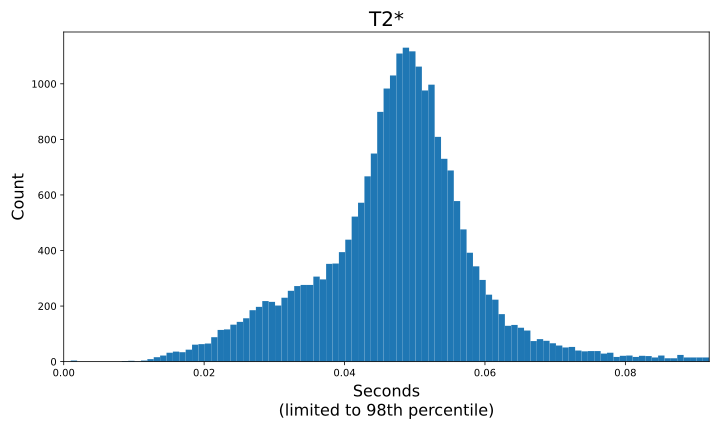

In [20]:
t2star_brain = SVG(filename='five-echo-dataset/tedana_external_regress_processed/figures/t2star_brain.svg')
t2star_histogram = SVG(filename='five-echo-dataset/tedana_external_regress_processed/figures/t2star_histogram.svg')

display(t2star_brain, t2star_histogram)

### S0

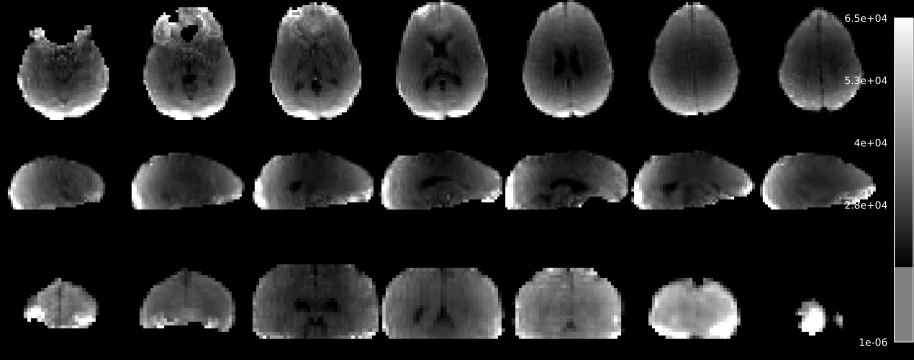

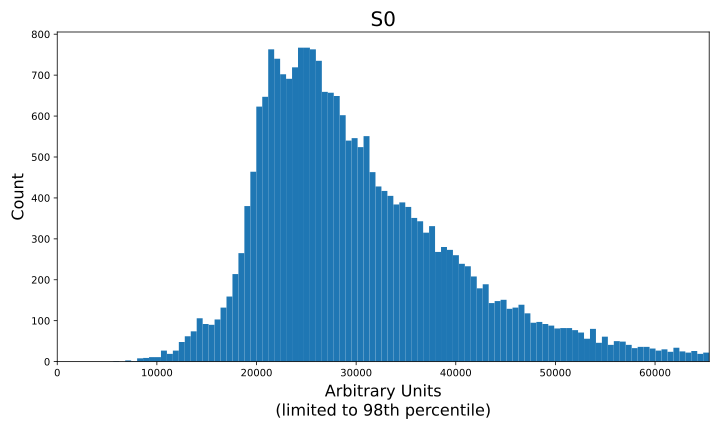

In [21]:
s0_brain = SVG(filename='five-echo-dataset/tedana_external_regress_processed/figures/s0_brain.svg')
s0_histogram = SVG(filename='five-echo-dataset/tedana_external_regress_processed/figures/s0_histogram.svg')

display(s0_brain, s0_histogram)

### T2* and S0 model fit (RMSE). (Scaled between 2nd and 98th percentiles)

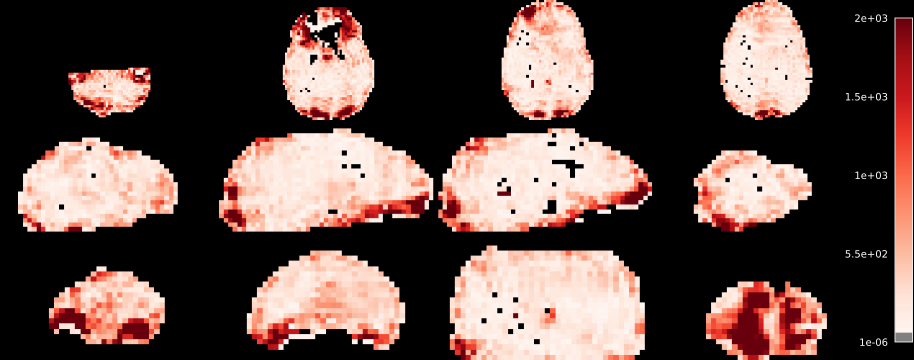

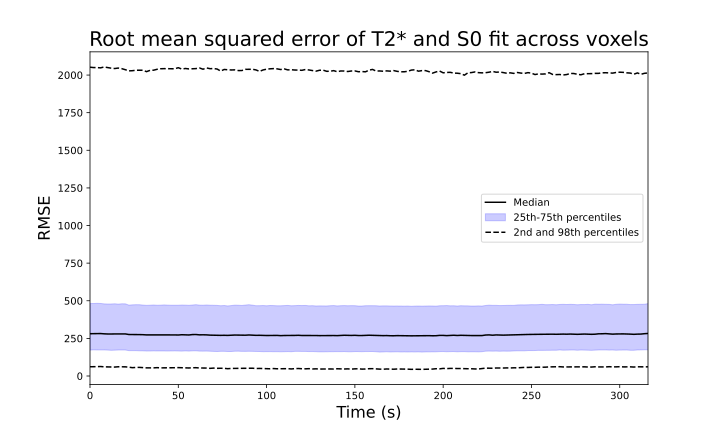

In [22]:
rmse_brain = SVG(filename='five-echo-dataset/tedana_external_regress_processed/figures/rmse_brain.svg')
rmse_timeseries = SVG(filename='five-echo-dataset/tedana_external_regress_processed/figures/rmse_timeseries.svg')

display(rmse_brain, rmse_timeseries)

### External regressors

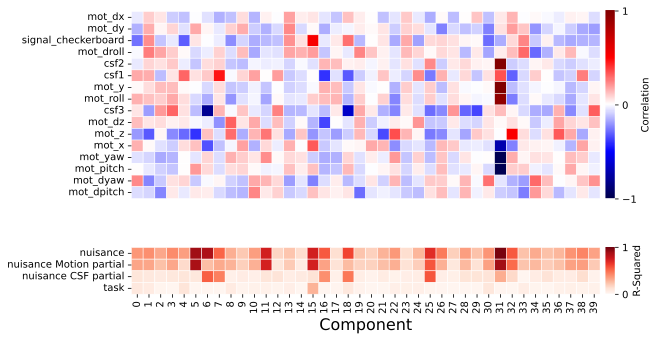

In [23]:
SVG(filename='five-echo-dataset/tedana_external_regress_processed/figures/confound_correlations.svg')

#### Dependencies in Jupyter/Python
- Using the package [watermark](https://github.com/rasbt/watermark) to document system environment and software versions used in this notebook, alongside the Neurodesktop version extracted from the `JUPYTER_IMAGE` or `NEURODESKTOP_VERSION` environment variables.

In [24]:
import os

%load_ext watermark

%watermark
%watermark --iversions

neurodesktop_version = (
    os.environ.get('JUPYTER_IMAGE', '').split(':')[-1] or
    os.environ.get('NEURODESKTOP_VERSION', 'unknown')
)

print(f"Neurodesktop version: {neurodesktop_version}")

Last updated: 2026-10-07T12:07:07.866978+00:00

Python implementation: CPython
Python version       : 3.13.15
IPython version      : 9.17.1

Compiler    : GCC 15.3.0
OS          : Linux
Release     : 6.8.0-111-generic
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit

IPython: 9.17.1
tedana : 26.0.3

Neurodesktop version: 2026-10-05
